# Credit Card Fraud: load local data and train models
Reads `data/creditcard.csv` (from https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) and trains fraud classifiers.

In [1]:
from pathlib import Path

DATA_DIR = Path.cwd().parent / "data"
CSV_PATH = DATA_DIR / "creditcard.csv"
OUTPUT_DIR = DATA_DIR.parent / "output"
OUTPUT_DIR.mkdir(exist_ok=True)
assert CSV_PATH.exists(), f"Missing {CSV_PATH}"

In [2]:
import pandas as pd

df = pd.read_csv(CSV_PATH)
df["small_spend"] = (df["Amount"] <= 10).astype(int)
df["large_spend"] = (df["Amount"] >= 100).astype(int)
df["hour"] = ((df["Time"] // 3600) % 24).astype(int)
print(df.shape)
print(df["Class"].value_counts(normalize=True))
df.head()

(284807, 34)
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V24,V25,V26,V27,V28,Amount,Class,small_spend,large_spend,hour
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,0,1,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,1,0,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,0,1,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0,0,1,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0,0,0,0


## Exploratory analysis

small_spend: fraud rate % by value -> {0: 0.132, 1: 0.248}  (chi2 p-value = 1.13e-12)
large_spend: fraud rate % by value -> {0: 0.159, 1: 0.227}  (chi2 p-value = 0.000635)
Mann-Whitney U on Amount: p-value = 8.58e-06


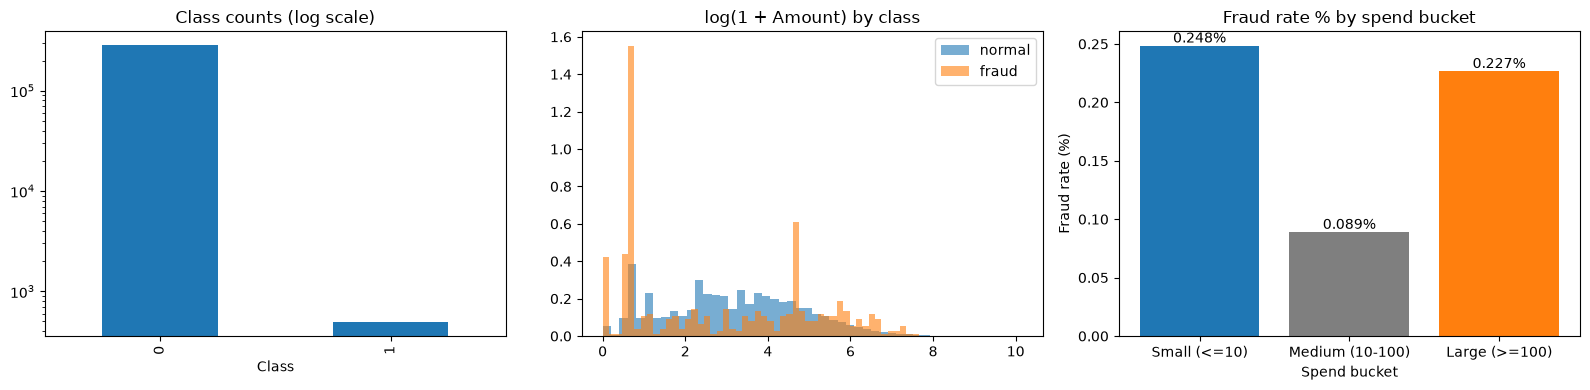

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Fraud rate by spend bucket + chi-square tests
for col in ["small_spend", "large_spend"]:
    table = pd.crosstab(df[col], df["Class"])
    chi2, p, _, _ = stats.chi2_contingency(table)
    rates = df.groupby(col)["Class"].mean() * 100
    print(f"{col}: fraud rate % by value -> {rates.round(3).to_dict()}  (chi2 p-value = {p:.3g})")

# Amount differs between classes?
u, p = stats.mannwhitneyu(df.loc[df.Class == 1, "Amount"], df.loc[df.Class == 0, "Amount"])
print(f"Mann-Whitney U on Amount: p-value = {p:.3g}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df["Class"].value_counts().plot.bar(ax=axes[0], logy=True, title="Class counts (log scale)")

for c, label in [(0, "normal"), (1, "fraud")]:
    axes[1].hist(np.log1p(df.loc[df.Class == c, "Amount"]), bins=50, alpha=0.6, density=True, label=label)
axes[1].set_title("log(1 + Amount) by class")
axes[1].legend()

bucket = df.assign(
    bucket=np.select([df.small_spend == 1, df.large_spend == 1], ["Small (<=10)", "Large (>=100)"], "Medium (10-100)")
).groupby("bucket")["Class"].mean().reindex(["Small (<=10)", "Medium (10-100)", "Large (>=100)"]) * 100
bars = axes[2].bar(bucket.index, bucket.values, color=["tab:blue", "tab:gray", "tab:orange"])
axes[2].bar_label(bars, fmt="%.3f%%")
axes[2].set_title("Fraud rate % by spend bucket")
axes[2].set_xlabel("Spend bucket")
axes[2].set_ylabel("Fraud rate (%)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()

**Summary:** Fraud is extremely rare (~0.17% of transactions), so accuracy alone would be misleading. Fraud transactions tend to have different amounts than normal ones, and the spend-bucket chart shows small purchases (<=10) have the highest fraud rate (~0.25%), large purchases (>=100) are next (~0.23%), and mid-range purchases are lowest (~0.09%).

## Transaction amount by fraud label

Amounts are strongly right-skewed, so this boxplot compares `log1p(Amount)` for normal and fraudulent transactions. This keeps zero amounts valid while making the central distributions easier to compare.

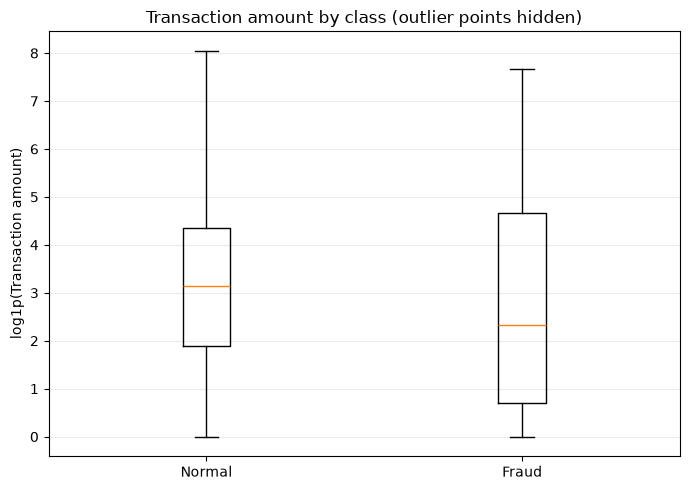

        25th percentile  Median  75th percentile  95th percentile  99th percentile
Normal             5.65   22.00            77.05           364.41          1016.97
Fraud              1.00    9.25           105.89           640.90          1357.43


In [4]:
amount_groups = [np.log1p(df.loc[df["Class"] == label, "Amount"]) for label in (0, 1)]
fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot(amount_groups, tick_labels=["Normal", "Fraud"], showfliers=False)
ax.set(ylabel="log1p(Transaction amount)", title="Transaction amount by class (outlier points hidden)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "amount_boxplot_by_class.png", dpi=150, bbox_inches="tight")
plt.show()
amount_quantiles = df.groupby("Class")["Amount"].quantile([0.25, 0.50, 0.75, 0.95, 0.99]).unstack()
amount_quantiles.index = ["Normal", "Fraud"]
amount_quantiles.columns = ["25th percentile", "Median", "75th percentile", "95th percentile", "99th percentile"]
print(amount_quantiles.round(2).to_string())

**Interpretation:** Compare the median and interquartile range in the boxplot to see how typical transaction amounts differ by label. The whiskers show the central distribution without plotting the many individual outliers; the quantile table includes the 95th and 99th percentiles to show the tails.

## Fraud patterns across two PCA features

`V14` and `V10` are among the strongest features in the existing model analysis. This scatter plot overlays every transaction, with legitimate transactions faded and fraud highlighted, to show their separation and overlap.

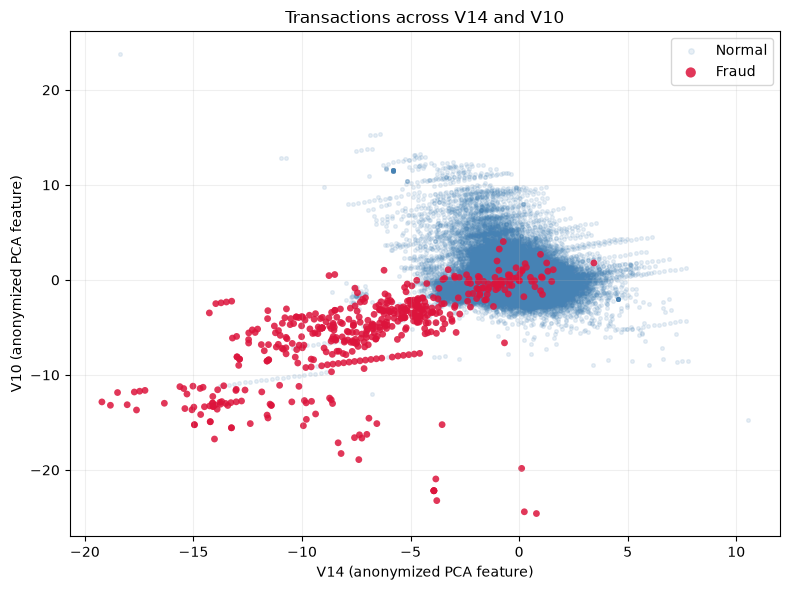

Transactions plotted: 284,807; frauds highlighted: 492


In [5]:
normal = df["Class"] == 0
fraud = df["Class"] == 1
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df.loc[normal, "V14"], df.loc[normal, "V10"],
           s=7, alpha=0.12, color="steelblue", label="Normal")
ax.scatter(df.loc[fraud, "V14"], df.loc[fraud, "V10"],
           s=24, alpha=0.85, color="crimson", label="Fraud", edgecolors="none")
ax.set(xlabel="V14 (anonymized PCA feature)",
       ylabel="V10 (anonymized PCA feature)",
       title="Transactions across V14 and V10")
ax.grid(alpha=0.2)
ax.legend(markerscale=1.5)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "v14_v10_fraud_scatter.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Transactions plotted: {len(df):,}; frauds highlighted: {int(fraud.sum()):,}")

**Interpretation:** Look for regions where the highlighted fraud points separate from the faded normal transactions, and for areas where the classes overlap. Any separation is descriptive rather than a decision rule: these two anonymized components alone do not capture all the information used by the full classifier.

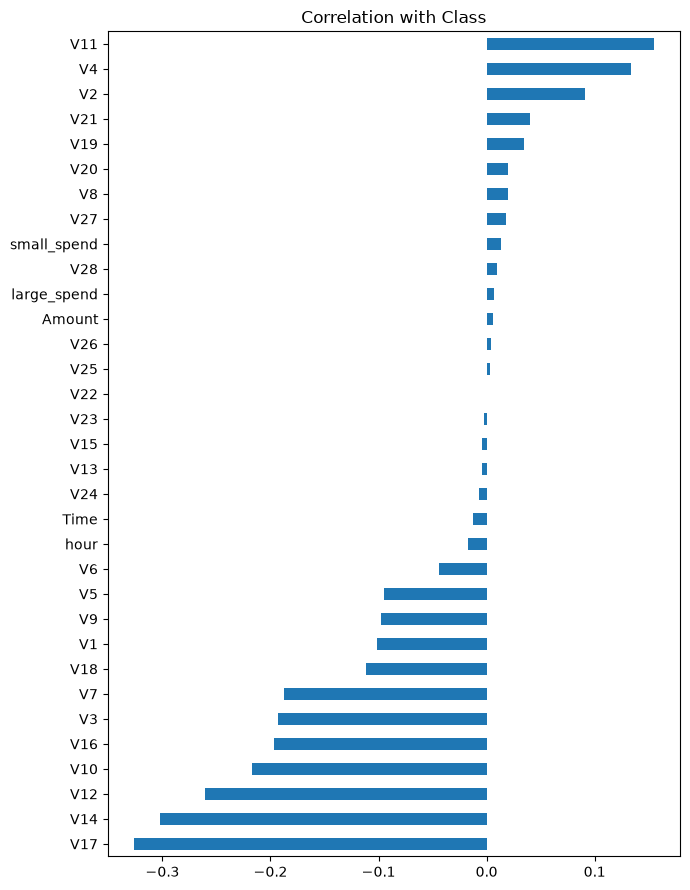

In [6]:
# Correlation of each feature with Class
corr = df.drop(columns="Class").corrwith(df["Class"]).sort_values()
corr.plot.barh(figsize=(7, 9), title="Correlation with Class")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "correlation_with_class.png", dpi=150, bbox_inches="tight")
plt.show()

**Summary:** V17, V14, V12 and V10 are the most negatively correlated with fraud (about -0.33 to -0.22), while V11 and V4 are the most positively correlated (about +0.15 and +0.13). No single feature is strongly correlated, so detecting fraud needs a combination of features.

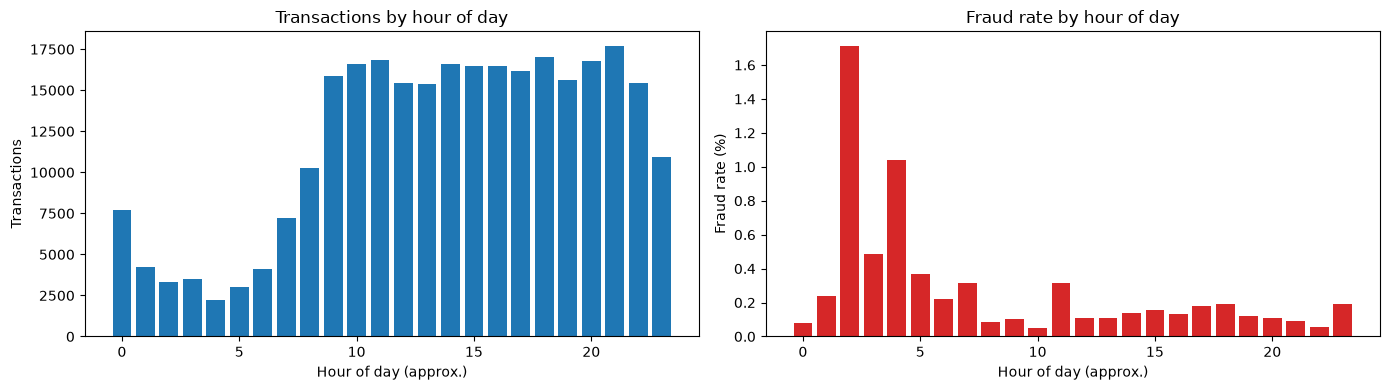

In [7]:
# Time = seconds since the first transaction; approximate hour of day
hour = df["hour"]
by_hour = df.groupby(hour)["Class"].agg(total="size", frauds="sum", rate="mean")
by_hour["rate"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(by_hour.index, by_hour["total"])
axes[0].set_title("Transactions by hour of day")
axes[0].set_xlabel("Hour of day (approx.)")
axes[0].set_ylabel("Transactions")

axes[1].bar(by_hour.index, by_hour["rate"], color="tab:red")
axes[1].set_title("Fraud rate by hour of day")
axes[1].set_xlabel("Hour of day (approx.)")
axes[1].set_ylabel("Fraud rate (%)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "hour_of_day.png", dpi=150, bbox_inches="tight")
plt.show()

**Summary:** Transaction volume is lowest overnight (hours ~2-5) and steady from ~9 to ~22. The fraud rate is the reverse: it peaks overnight, with ~1.7% at hour 2 and ~1.0% at hour 4, versus roughly 0.05-0.2% during the day. Fraud is concentrated when few normal transactions occur. Hour 0 is relative to the dataset's start, not a confirmed clock time.

## Train / test split

In [8]:
from sklearn.model_selection import train_test_split

X, y = df.drop(columns="Class"), df["Class"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)

(227845, 33) (56962, 33)


## Train and evaluate models

In [9]:
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, classification_report, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

MODEL_DIR = DATA_DIR.parent / "models"
MODEL_DIR.mkdir(exist_ok=True)

models = {
    "logreg": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "random_forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=42
    ),
}

probas = {}
for name, model in models.items():
    print(f"\n=== {name} ===")
    model.fit(X_train, y_train)
    probas[name] = model.predict_proba(X_test)[:, 1]
    print(classification_report(y_test, probas[name] > 0.5, digits=4))
    print("ROC AUC:", round(roc_auc_score(y_test, probas[name]), 4))
    print("PR AUC :", round(average_precision_score(y_test, probas[name]), 4))
    joblib.dump(model, MODEL_DIR / f"{name}.joblib")


=== logreg ===
              precision    recall  f1-score   support

           0     0.9998    0.9737    0.9866     56864
           1     0.0561    0.9082    0.1057        98

    accuracy                         0.9736     56962
   macro avg     0.5280    0.9409    0.5461     56962
weighted avg     0.9982    0.9736    0.9851     56962

ROC AUC: 0.974
PR AUC : 0.7257

=== random_forest ===
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     56864
           1     0.9605    0.7449    0.8391        98

    accuracy                         0.9995     56962
   macro avg     0.9800    0.8724    0.9194     56962
weighted avg     0.9995    0.9995    0.9995     56962

ROC AUC: 0.9521
PR AUC : 0.8665


## Precision-recall curves

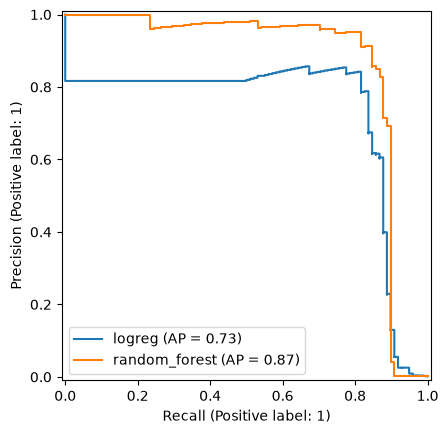

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots()
for name, p in probas.items():
    PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=ax)
plt.savefig(OUTPUT_DIR / "precision_recall_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Summary:** The random forest holds higher precision across most recall levels (PR AUC ~0.87 vs ~0.73 for logistic regression), so it is the better model overall. Logistic regression only matches it at lower precision.

## Confusion matrices

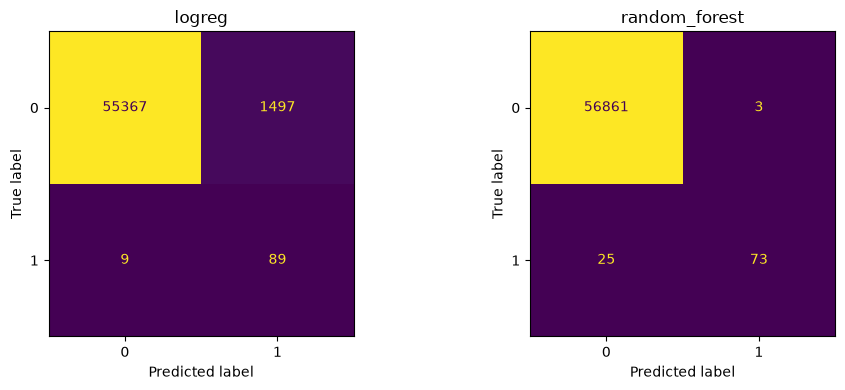

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, len(probas), figsize=(5 * len(probas), 4))
for ax, (name, p) in zip(axes, probas.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p > 0.5, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

**Summary:** At the 0.5 threshold, logistic regression catches 89 of 98 frauds but raises ~1,500 false alarms. The random forest raises only 3 false alarms but misses 25 frauds (catches 73). It is a trade-off between catching more fraud and bothering fewer customers.

## Feature importance (random forest)

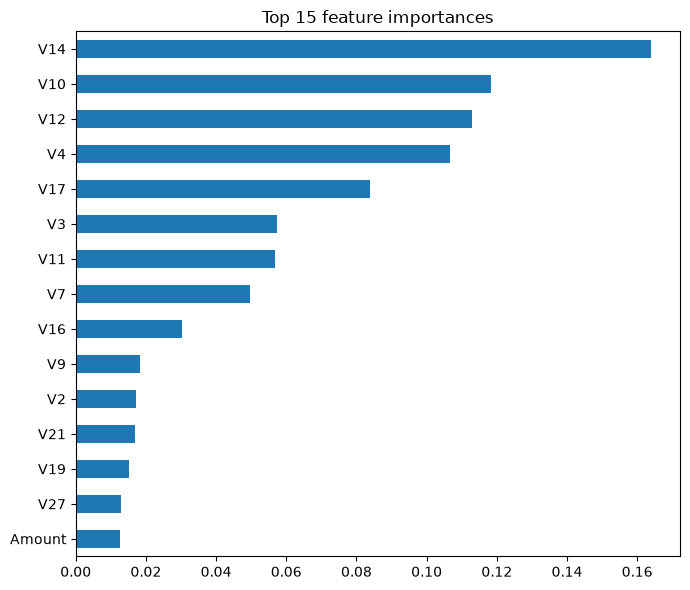

In [12]:
importances = pd.Series(models["random_forest"].feature_importances_, index=X.columns)
importances.sort_values().tail(15).plot.barh(figsize=(7, 6), title="Top 15 feature importances")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

**Summary:** V14 is by far the most important feature for the random forest (~0.16), followed by V10, V12, V4 and V17. These match the features most correlated with fraud. The engineered features add little: `hour` ~0.004, `small_spend` ~0.0015 and `large_spend` ~0.0007.

## Threshold analysis
Precision, recall and F1 as the decision threshold changes.

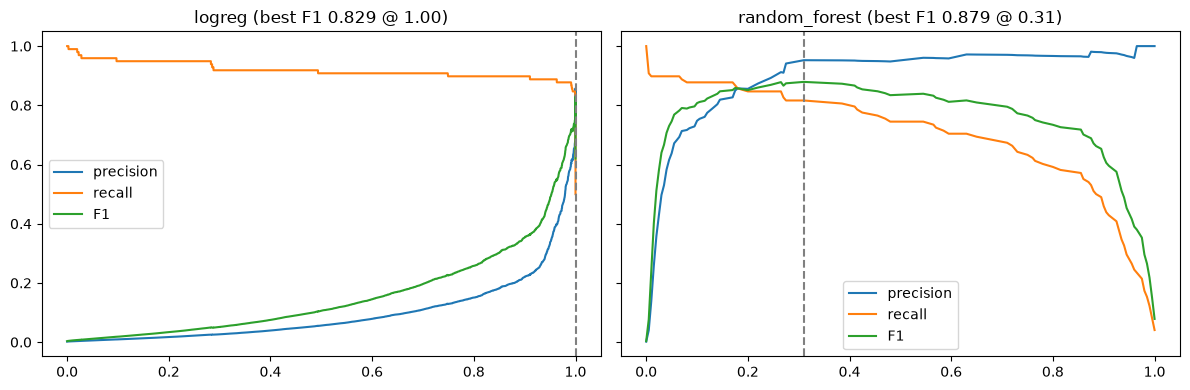

In [13]:
from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, len(probas), figsize=(6 * len(probas), 4), sharey=True)
for ax, (name, p) in zip(axes, probas.items()):
    prec, rec, thr = precision_recall_curve(y_test, p)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    ax.plot(thr, prec[:-1], label="precision")
    ax.plot(thr, rec[:-1], label="recall")
    ax.plot(thr, f1, label="F1")
    ax.axvline(thr[f1.argmax()], ls="--", color="gray")
    ax.set_title(f"{name} (best F1 {f1.max():.3f} @ {thr[f1.argmax()]:.2f})")
    ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "threshold_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

**Summary:** Raising the threshold increases precision and lowers recall. The random forest reaches its best F1 (~0.88) at a threshold near 0.31, better than at the default 0.5. Logistic regression's best F1 (~0.83) needs a very high threshold, which shows its probabilities are poorly calibrated because of class weighting.

## Fraud capture at a fixed alert capacity

This curve shows the share of all test-set frauds found when reviewing the highest-scored transactions first. The table reports capture at a few alert-volume budgets, making the comparison useful when investigation capacity is limited.

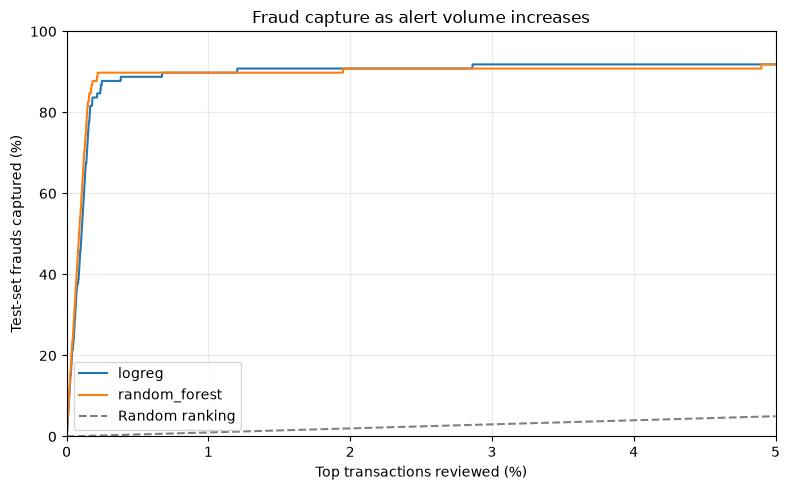

,model,alert budget (%),transactions reviewed,frauds caught,fraud capture (%)
0,logreg,0.1,57,46,46.9
1,logreg,0.5,285,87,88.8
2,logreg,1.0,570,88,89.8
3,logreg,2.0,1140,89,90.8
4,random_forest,0.1,57,55,56.1
5,random_forest,0.5,285,88,89.8
6,random_forest,1.0,570,88,89.8
7,random_forest,2.0,1140,89,90.8


In [14]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

y_true = np.asarray(y_test)
n_transactions = len(y_true)
n_frauds = int(y_true.sum())
alert_budgets = [0.1, 0.5, 1.0, 2.0]
capture_rows = []

fig, ax = plt.subplots(figsize=(8, 5))
for name, scores in probas.items():
    ranked_indices = np.argsort(scores)[::-1]
    cumulative_capture = np.cumsum(y_true[ranked_indices]) / n_frauds * 100
    alert_share = np.arange(1, n_transactions + 1) / n_transactions * 100
    visible = alert_share <= 5
    ax.plot(alert_share[visible], cumulative_capture[visible], label=name)

    for budget in alert_budgets:
        n_alerts = math.ceil(n_transactions * budget / 100)
        caught = int(y_true[ranked_indices[:n_alerts]].sum())
        capture_rows.append({
            "model": name,
            "alert budget (%)": budget,
            "transactions reviewed": n_alerts,
            "frauds caught": caught,
            "fraud capture (%)": caught / n_frauds * 100,
        })

ax.plot([0, 5], [0, 5], linestyle="--", color="gray", label="Random ranking")
ax.set(xlim=(0, 5), ylim=(0, 100),
       xlabel="Top transactions reviewed (%)",
       ylabel="Test-set frauds captured (%)",
       title="Fraud capture as alert volume increases")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_k_fraud_capture.png", dpi=150, bbox_inches="tight")
plt.show()

display(pd.DataFrame(capture_rows).round({"fraud capture (%)": 1}))

**Interpretation:** With a 0.1% review budget (57 transactions), the random forest captures 55 of 98 test frauds (56.1%), compared with 46 (46.9%) for logistic regression. At a 0.5% budget (285 transactions), the models capture 88 (89.8%) and 87 (88.8%), respectively. The random forest has a slight edge at tight alert capacity; above that, the models are similar.

## Probability calibration

A calibrated model's predictions agree with observed fraud frequencies: among transactions assigned about 0.2 probability, roughly 20% should be fraud. Quantile bins keep the number of transactions per bin similar despite the rare fraud class; the Brier score provides a single overall measure, where lower is better.

logreg Brier score: 0.023899
random_forest Brier score: 0.000409
Prevalence-only baseline Brier score: 0.001717


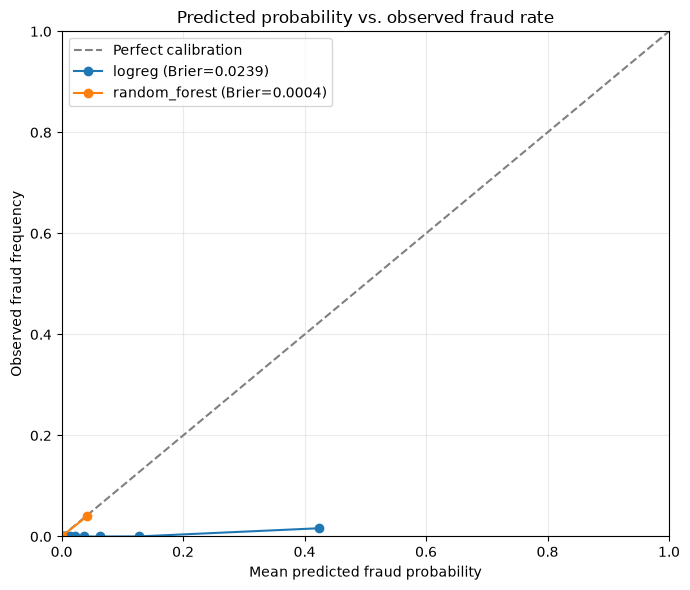

In [15]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")

for name, scores in probas.items():
    fraction_positive, mean_predicted = calibration_curve(
        y_test, scores, n_bins=10, strategy="quantile"
    )
    brier = brier_score_loss(y_test, scores)
    ax.plot(mean_predicted, fraction_positive, marker="o", label=f"{name} (Brier={brier:.4f})")
    print(f"{name} Brier score: {brier:.6f}")

baseline_brier = brier_score_loss(y_test, np.full(len(y_test), np.mean(y_test)))
print(f"Prevalence-only baseline Brier score: {baseline_brier:.6f}")
ax.set(xlim=(0, 1), ylim=(0, 1),
       xlabel="Mean predicted fraud probability",
       ylabel="Observed fraud frequency",
       title="Predicted probability vs. observed fraud rate")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "calibration_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** The random forest has a Brier score of 0.000409, lower than the prevalence-only baseline (0.001717); logistic regression scores 0.023899, indicating much poorer probability estimates on this test split. Use the diagonal to judge calibration in each probability bin. Because the fraud class is rare, read Brier scores alongside the precision-recall and alert-capacity results rather than as the only model-quality measure.